In [1]:
from google.colab import drive
drive.mount('/content/drive')

!mkdir -p /content/data
!unzip -oq "/content/drive/MyDrive/WBC-Folder/PBC_dataset_normal_DIB.zip" -x "__MACOSX/*" -d /content/data
!git clone -q https://github.com/asn104610/WBC-Differentiator-v.1.git /content/repo

import os, pandas as pd, torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from PIL import Image

root = "/content/data/PBC_dataset_normal_DIB"

def fix_path(p, label):
    name = p.replace("\\", "/").split("/")[-1]
    return f"{root}/{label}/{name}"

def load_split(name):
    d = pd.read_csv(f"/content/repo/{name}.csv")
    d["path"] = [fix_path(p, l) for p, l in zip(d["path"], d["label"])]
    return d

train_df, val_df, test_df = load_split("train"), load_split("val"), load_split("test")
classes = sorted(train_df["label"].unique())
class_to_idx = {c: i for i, c in enumerate(classes)}

tfm = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

class CellDataset(Dataset):
    def __init__(self, d):
        self.paths = d["path"].tolist()
        self.labels = [class_to_idx[l] for l in d["label"]]
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        return tfm(Image.open(self.paths[i]).convert("RGB")), self.labels[i]

val_loader = DataLoader(CellDataset(val_df), batch_size=64, shuffle=False, num_workers=2)
test_loader = DataLoader(CellDataset(test_df), batch_size=64, shuffle=False, num_workers=2)

device = "cuda"
model = models.resnet18(weights=None)
model.fc = nn.Linear(model.fc.in_features, len(classes))
model.load_state_dict(torch.load("/content/drive/MyDrive/WBC-Folder/resnet18_wbc_v1.pt", map_location=device))
model = model.to(device).eval()
print("ready:", classes)

Mounted at /content/drive
ready: ['basophil', 'eosinophil', 'erythroblast', 'ig', 'lymphocyte', 'monocyte', 'neutrophil', 'platelet']


In [2]:
import copy

aug_tfm = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

class AugDataset(CellDataset):
    def __getitem__(self, i):
        return aug_tfm(Image.open(self.paths[i]).convert("RGB")), self.labels[i]

train_loader = DataLoader(AugDataset(train_df), batch_size=64, shuffle=True, num_workers=2)

model2 = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
model2.fc = nn.Linear(model2.fc.in_features, len(classes))
model2 = model2.to(device)

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model2.parameters(), lr=1e-4)

best_acc, best_state = 0, None
for epoch in range(6):
    model2.train()
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        loss_fn(model2(x), y).backward()
        optimizer.step()
    model2.eval()
    correct = 0
    with torch.no_grad():
        for x, y in val_loader:
            x, y = x.to(device), y.to(device)
            correct += (model2(x).argmax(1) == y).sum().item()
    acc = correct / len(val_df)
    print(f"epoch {epoch+1}: val accuracy = {acc:.3f}")
    if acc > best_acc:
        best_acc, best_state = acc, copy.deepcopy(model2.state_dict())

torch.save(best_state, "/content/drive/MyDrive/WBC-Folder/resnet18_wbc_v2.pt")
print("best val accuracy:", round(best_acc, 3), "- saved v2")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 130MB/s]


epoch 1: val accuracy = 0.971
epoch 2: val accuracy = 0.978
epoch 3: val accuracy = 0.984
epoch 4: val accuracy = 0.975
epoch 5: val accuracy = 0.987
epoch 6: val accuracy = 0.985
best val accuracy: 0.987 - saved v2


In [3]:
from sklearn.metrics import classification_report

model2.load_state_dict(best_state)
model2.eval()

preds2, truths2 = [], []
with torch.no_grad():
    for x, y in test_loader:
        preds2 += model2(x.to(device)).argmax(1).cpu().tolist()
        truths2 += y.tolist()

acc2 = sum(p == t for p, t in zip(preds2, truths2)) / len(truths2)
print("v2 test accuracy:", round(acc2, 3), "(v1 was 0.984)")
print(classification_report(truths2, preds2, target_names=classes, digits=3))

v2 test accuracy: 0.986 (v1 was 0.984)
              precision    recall  f1-score   support

    basophil      0.989     0.995     0.992       183
  eosinophil      1.000     0.998     0.999       467
erythroblast      0.991     0.987     0.989       233
          ig      0.962     0.982     0.971       434
  lymphocyte      0.989     0.973     0.981       182
    monocyte      0.964     0.995     0.979       213
  neutrophil      0.992     0.968     0.980       500
    platelet      0.997     0.997     0.997       352

    accuracy                          0.986      2564
   macro avg      0.985     0.987     0.986      2564
weighted avg      0.986     0.986     0.986      2564



In [ ]:
preds = []
with torch.no_grad():
    for x, y in val_loader:
        preds += model(x.to(device)).argmax(1).cpu().tolist()
val_df["pred"] = [classes[i] for i in preds]
print("val accuracy:", round((val_df["pred"] == val_df["label"]).mean(), 3))

val accuracy: 0.981


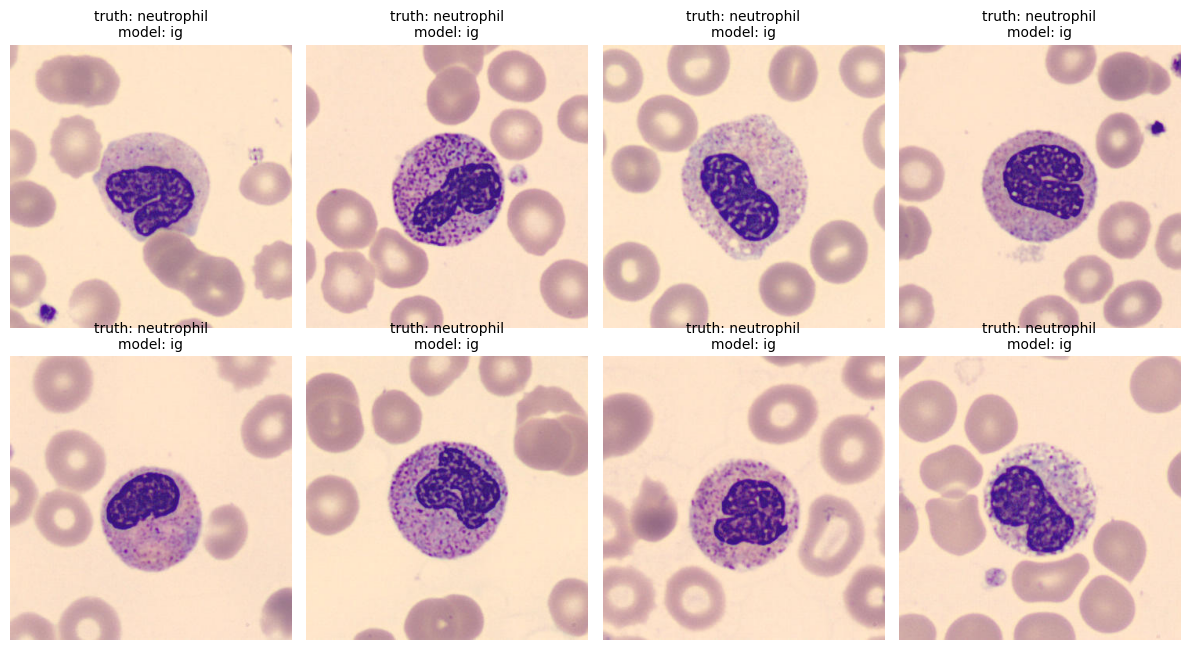

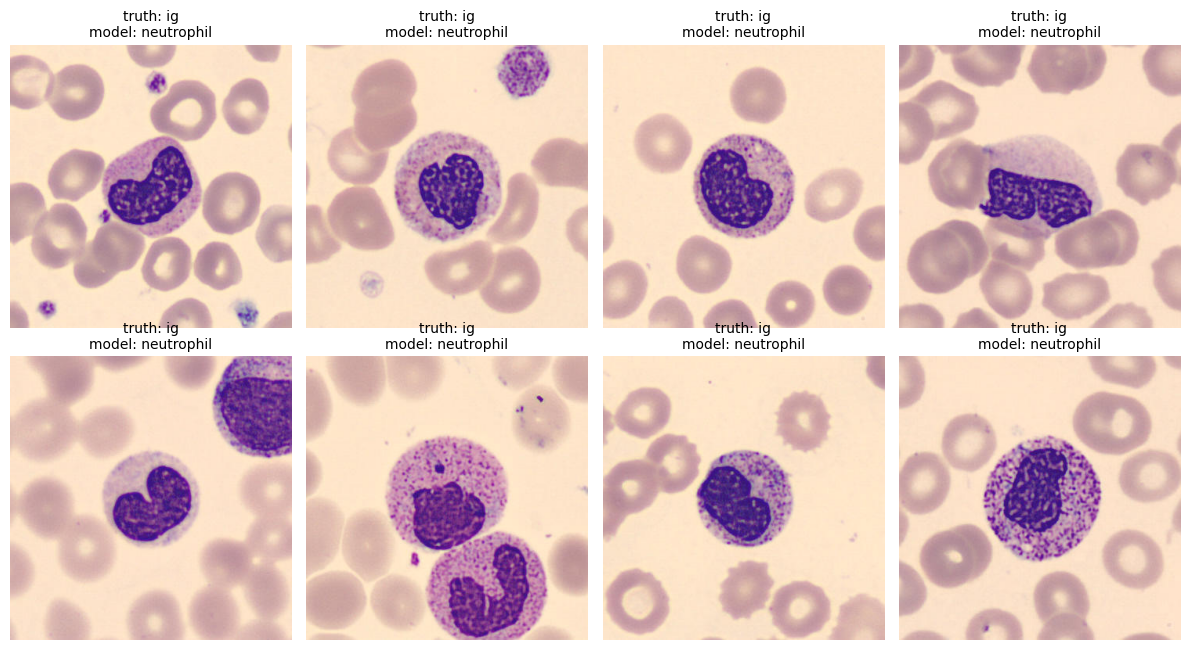

In [ ]:
import matplotlib.pyplot as plt

def show(true_label, pred_label, n=8):
    rows = val_df[(val_df["label"] == true_label) & (val_df["pred"] == pred_label)].head(n)
    fig, axes = plt.subplots(2, 4, figsize=(12, 6.5))
    for ax in axes.flat:
        ax.axis("off")
    for ax, (_, r) in zip(axes.flat, rows.iterrows()):
        ax.imshow(Image.open(r["path"]))
        ax.set_title(f"truth: {r['label']}\nmodel: {r['pred']}", fontsize=10)
    plt.tight_layout()
    plt.show()

show("neutrophil", "ig")
show("ig", "neutrophil")

In [ ]:
from sklearn.metrics import classification_report

test_preds, test_truths = [], []
with torch.no_grad():
    for x, y in test_loader:
        test_preds += model(x.to(device)).argmax(1).cpu().tolist()
        test_truths += y.tolist()

acc = sum(p == t for p, t in zip(test_preds, test_truths)) / len(test_truths)
print("test accuracy:", round(acc, 3))
print(classification_report(test_truths, test_preds, target_names=classes, digits=3))

test accuracy: 0.984
              precision    recall  f1-score   support

    basophil      0.968     0.995     0.981       183
  eosinophil      1.000     1.000     1.000       467
erythroblast      0.991     0.974     0.983       233
          ig      0.974     0.959     0.966       434
  lymphocyte      0.973     0.989     0.981       182
    monocyte      0.977     0.995     0.986       213
  neutrophil      0.978     0.976     0.977       500
    platelet      0.997     0.997     0.997       352

    accuracy                          0.984      2564
   macro avg      0.982     0.986     0.984      2564
weighted avg      0.984     0.984     0.984      2564

